In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, precision_score, recall_score,
    f1_score, confusion_matrix, accuracy_score, classification_report
)
import warnings, os, time

warnings.filterwarnings('ignore')

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv, BatchNorm

np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}, PyG: {torch_geometric.__version__}")

Device: cpu
PyTorch: 2.9.1+cpu, PyG: 2.7.0


In [2]:

print("\n" + "="*70)
print("SECTION 1: DATA LOADING")
print("="*70)

RAW_DATA_PATH = r"g:\pfe\MLA_PROJET_RL\combined_dataset_with_lateral_movement.xlsx"
DATA_DIR = 'feature_selection_outputs2'

print("Loading raw dataset...")
df_raw = pd.read_excel(RAW_DATA_PATH)
print(f"Raw dataset shape: {df_raw.shape}")

# Robust timestamp parsing (English + French locale)
raw_ts = df_raw['_source.@timestamp'].astype(str).str.strip()
clean_ts = raw_ts.str.replace('@', '', regex=False).str.strip()

fr_map = {
    r'^janv\.?\s*': '01 ', r'^f.vr?\.?\s*': '02 ', r'^mars\.?\s*': '03 ',
    r'^avr\.?\s*': '04 ', r'^mai\.?\s*': '05 ', r'^juin\.?\s*': '06 ',
    r'^juil\.?\s*': '07 ', r'^ao.t\.?\s*': '08 ', r'^sept?\.?\s*': '09 ',
    r'^oct\.?\s*': '10 ', r'^nov\.?\s*': '11 ', r'^d.c\.?\s*': '12 '
}
en_map = {
    r'^Jan': '01', r'^Feb': '02', r'^Mar': '03', r'^Apr': '04',
    r'^May': '05', r'^Jun': '06', r'^Jul': '07', r'^Aug': '08',
    r'^Sep': '09', r'^Oct': '10', r'^Nov': '11', r'^Dec': '12'
}
for pat, repl in {**en_map, **fr_map}.items():
    clean_ts = clean_ts.str.replace(pat, repl, regex=True)

df_raw['timestamp'] = pd.to_datetime(clean_ts, errors='coerce')
n_nat = df_raw['timestamp'].isna().sum()
if n_nat > 0:
    print(f"  {n_nat} unparseable timestamps - using dateutil fallback...")
    from dateutil import parser as dp
    for idx in df_raw[df_raw['timestamp'].isna()].index:
        try:
            df_raw.at[idx, 'timestamp'] = dp.parse(str(raw_ts.iloc[idx]).replace('@','').strip(), fuzzy=True)
        except Exception:
            pass
    still_nat = df_raw['timestamp'].isna().sum()
    if still_nat > 0:
        df_raw['timestamp'] = df_raw['timestamp'].fillna(df_raw['timestamp'].dropna().median())

df_raw = df_raw.sort_values('timestamp').reset_index(drop=True)

# Create simplified columns
df_raw['machine_name'] = df_raw['_source.agent.name'].fillna('unknown')
df_raw['machine_ip'] = df_raw['_source.agent.ip'].fillna('unknown')
df_raw['src_user'] = df_raw['_source.data.srcuser'].fillna('none').astype(str).str.replace("'","").str.replace('"','').str.strip()
df_raw['src_ip'] = df_raw['_source.data.srcip'].fillna('none')
df_raw['rule_level'] = pd.to_numeric(df_raw['_source.rule.level'], errors='coerce').fillna(0).astype(int)
df_raw['label'] = pd.to_numeric(df_raw['malicious'], errors='coerce').fillna(0).astype(int)

print(f"Loaded {len(df_raw)} alerts | Machines: {df_raw['machine_name'].unique().tolist()}")
print(f"Labels: {(df_raw['label']==0).sum()} benign, {(df_raw['label']==1).sum()} malicious ({df_raw['label'].mean()*100:.1f}%)")


SECTION 1: DATA LOADING
Loading raw dataset...
Raw dataset shape: (116016, 179)
Loaded 116016 alerts | Machines: ['ubuntu', 'machine-1', 'machine-2', 'machine-3', 'Machine-1-New']
Labels: 90598 benign, 25418 malicious (21.9%)


In [3]:

print("\n" + "="*70)
print("SECTION 2: TOP 25 FEATURES")
print("="*70)

X_full_df = pd.read_parquet(f'{DATA_DIR}/feature_matrix_no_leakage.parquet')

log_emb_cols = sorted([c for c in X_full_df.columns if c.startswith('log_secbert_emb_')])
cmd_emb_cols = sorted([c for c in X_full_df.columns if c.startswith('cmd_secbert_emb_')])

fi = pd.read_csv(f'{DATA_DIR}/feature_importance_malicious_detection.csv')
fi = fi.sort_values('Average_Score', ascending=False)
fi_ind = fi[~fi['Feature'].str.startswith(('log_secbert_emb_', 'cmd_secbert_emb_'))]
fi_ind = fi_ind.sort_values('Average_Score', ascending=False)

N_IND = 23  # + 2 embedding groups = 25 features
top_features = fi_ind['Feature'].head(N_IND).tolist()
selected_cols = top_features + log_emb_cols + cmd_emb_cols
X_sel = X_full_df[selected_cols]

# Align sizes
min_len = min(len(df_raw), len(X_sel))
df_raw = df_raw.head(min_len).reset_index(drop=True)
X_sel = X_sel.head(min_len).reset_index(drop=True)

X_sel = X_sel.copy()
X_sel['rule_level'] = df_raw['rule_level'].values
y_labels = df_raw['label'].values

print(f"Features: {X_sel.shape[1]} dims (25 features: {N_IND} individual + log_emb + cmd_emb + rule_level)")
print(f"Malicious: {(y_labels==1).sum():,} ({(y_labels==1).mean()*100:.1f}%)")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sel.values.astype(np.float32))


SECTION 2: TOP 25 FEATURES
Features: 56 dims (25 features: 23 individual + log_emb + cmd_emb + rule_level)
Malicious: 25,396 (21.9%)


In [4]:

print("\n" + "="*70)
print("SECTION 3: GRAPH CONSTRUCTION (VECTORIZED)")
print("="*70)

INTRA_WINDOW_SEC = 30 * 60   # 30 minutes
CROSS_WINDOW_SEC = 30 * 60   # 30 minutes
MAX_INTRA = 3
MAX_CROSS = 5

t0 = time.time()
timestamps_sec = (df_raw['timestamp'] - df_raw['timestamp'].min()).dt.total_seconds().values
machine_ids = pd.Categorical(df_raw['machine_name']).codes
user_strs = df_raw['src_user'].values
ip_strs = df_raw['src_ip'].values

edges_src, edges_dst = [], []

# 1. Intra-machine temporal edges (vectorized per machine)
print("  [1/3] Intra-machine temporal edges...")
for m_id in np.unique(machine_ids):
    mask = machine_ids == m_id
    idxs = np.where(mask)[0]
    ts = timestamps_sec[idxs]
    order = np.argsort(ts)
    idxs = idxs[order]
    ts = ts[order]
    
    for i in range(len(idxs)):
        count = 0
        for j in range(i+1, len(idxs)):
            if ts[j] - ts[i] > INTRA_WINDOW_SEC:
                break
            if count >= MAX_INTRA:
                break
            edges_src.extend([idxs[i], idxs[j]])
            edges_dst.extend([idxs[j], idxs[i]])
            count += 1

n_intra = len(edges_src) // 2
print(f"        {n_intra:,} edge pairs ({time.time()-t0:.1f}s)")

# 2. Cross-machine user edges (lateral movement)  
print("  [2/3] Cross-machine user edges...")
t1 = time.time()
n_cross_user = 0

# Group by user, only process users on multiple machines
user_machine_df = df_raw[['src_user', 'machine_name']].copy()
user_machine_df['idx'] = np.arange(len(df_raw))
user_machine_df['ts'] = timestamps_sec
user_machine_df['mid'] = machine_ids

multi_machine_users = []
for u, g in user_machine_df[user_machine_df['src_user'] != 'none'].groupby('src_user'):
    if g['mid'].nunique() >= 2:
        multi_machine_users.append(u)

print(f"        Users on multiple machines: {len(multi_machine_users)}")

for user in multi_machine_users:
    mask = user_strs == user
    idxs = np.where(mask)[0]
    ts = timestamps_sec[idxs]
    mids = machine_ids[idxs]
    order = np.argsort(ts)
    idxs, ts, mids = idxs[order], ts[order], mids[order]
    
    for i in range(len(idxs)):
        count = 0
        for j in range(i+1, len(idxs)):
            if ts[j] - ts[i] > CROSS_WINDOW_SEC:
                break
            if count >= MAX_CROSS:
                break
            if mids[i] != mids[j]:  # Different machines
                edges_src.extend([idxs[i], idxs[j]])
                edges_dst.extend([idxs[j], idxs[i]])
                n_cross_user += 1
                count += 1

print(f"        {n_cross_user:,} edge pairs ({time.time()-t1:.1f}s)")

# 3. Cross-machine IP edges
print("  [3/3] Cross-machine IP edges...")
t2 = time.time()
n_cross_ip = 0

multi_machine_ips = []
for ip, g in df_raw[(df_raw['src_ip'] != 'none') & (df_raw['src_ip'] != '')].groupby('src_ip'):
    if g['machine_name'].nunique() >= 2:
        multi_machine_ips.append(ip)

print(f"        IPs on multiple machines: {len(multi_machine_ips)}")

for ip in multi_machine_ips:
    mask = ip_strs == ip
    idxs = np.where(mask)[0]
    ts = timestamps_sec[idxs]
    mids = machine_ids[idxs]
    order = np.argsort(ts)
    idxs, ts, mids = idxs[order], ts[order], mids[order]
    
    for i in range(len(idxs)):
        count = 0
        for j in range(i+1, len(idxs)):
            if ts[j] - ts[i] > CROSS_WINDOW_SEC:
                break
            if count >= MAX_CROSS:
                break
            if mids[i] != mids[j]:
                edges_src.extend([idxs[i], idxs[j]])
                edges_dst.extend([idxs[j], idxs[i]])
                n_cross_ip += 1
                count += 1

print(f"        {n_cross_ip:,} edge pairs ({time.time()-t2:.1f}s)")

# Self-loops
n_nodes = len(df_raw)
edges_src.extend(list(range(n_nodes)))
edges_dst.extend(list(range(n_nodes)))

edge_index = torch.tensor([edges_src, edges_dst], dtype=torch.long)
total_edges = edge_index.shape[1]

print(f"\n{'='*50}")
print(f"  GRAPH STATISTICS")
print(f"{'='*50}")
print(f"  Nodes:     {n_nodes:,}")
print(f"  Edges:     {total_edges:,}")
print(f"    Intra:   {n_intra*2:,}")
print(f"    User:    {n_cross_user*2:,}")
print(f"    IP:      {n_cross_ip*2:,}")
print(f"    Self:    {n_nodes:,}")
print(f"  Avg deg:   {total_edges/n_nodes:.1f}")
print(f"  Time:      {time.time()-t0:.1f}s")
print(f"{'='*50}")


SECTION 3: GRAPH CONSTRUCTION (VECTORIZED)
  [1/3] Intra-machine temporal edges...
        346,504 edge pairs (1.3s)
  [2/3] Cross-machine user edges...
        Users on multiple machines: 22
        96,087 edge pairs (269.5s)
  [3/3] Cross-machine IP edges...
        IPs on multiple machines: 3
        151,168 edge pairs (627.7s)

  GRAPH STATISTICS
  Nodes:     115,726
  Edges:     1,303,244
    Intra:   693,008
    User:    192,174
    IP:      302,336
    Self:    115,726
  Avg deg:   11.3
  Time:      899.1s


In [5]:

print("\n" + "="*70)
print("SECTION 4: STRATIFIED TRAIN / VAL / TEST SPLIT")
print("="*70)

n_total = len(df_raw)
indices = np.arange(n_total)

# Always use stratified split to ensure ~22% malicious in each split
idx_train, idx_temp = train_test_split(indices, test_size=0.30, stratify=y_labels, random_state=42)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y_labels[idx_temp], random_state=42)

train_mask = torch.zeros(n_total, dtype=torch.bool)
val_mask = torch.zeros(n_total, dtype=torch.bool)
test_mask = torch.zeros(n_total, dtype=torch.bool)
train_mask[idx_train] = True
val_mask[idx_val] = True
test_mask[idx_test] = True

print(f"Train: {len(idx_train):,} ({y_labels[idx_train].mean()*100:.1f}% mal, {y_labels[idx_train].sum():,} mal)")
print(f"Val:   {len(idx_val):,} ({y_labels[idx_val].mean()*100:.1f}% mal, {y_labels[idx_val].sum():,} mal)")
print(f"Test:  {len(idx_test):,} ({y_labels[idx_test].mean()*100:.1f}% mal, {y_labels[idx_test].sum():,} mal)")

# Build PyG Data
x = torch.tensor(X_scaled, dtype=torch.float)
y = torch.tensor(y_labels, dtype=torch.float)
graph_data = Data(x=x, edge_index=edge_index, y=y,
                  train_mask=train_mask, val_mask=val_mask, test_mask=test_mask)
print(f"\n{graph_data}")


SECTION 4: STRATIFIED TRAIN / VAL / TEST SPLIT
Train: 81,008 (21.9% mal, 17,777 mal)
Val:   17,359 (21.9% mal, 3,810 mal)
Test:  17,359 (21.9% mal, 3,809 mal)

Data(x=[115726, 56], edge_index=[2, 1303244], y=[115726], train_mask=[115726], val_mask=[115726], test_mask=[115726])


In [6]:

print("\n" + "="*70)
print("SECTION 5: GNN MODEL")
print("="*70)


class APTPropagationGNN(nn.Module):
    """GraphSAGE for alert-level APT propagation detection."""
    def __init__(self, in_ch, hid=128, layers=3, drop=0.3):
        super().__init__()
        self.layers = layers
        self.drop = drop
        self.convs = nn.ModuleList()
        self.bns = nn.ModuleList()
        
        self.convs.append(SAGEConv(in_ch, hid))
        self.bns.append(BatchNorm(hid))
        for _ in range(layers - 1):
            self.convs.append(SAGEConv(hid, hid))
            self.bns.append(BatchNorm(hid))
        
        self.head = nn.Sequential(
            nn.Linear(hid, 64), nn.ReLU(), nn.Dropout(drop),
            nn.Linear(64, 1),
        )

    def forward(self, x, edge_index):
        for i in range(self.layers):
            x_in = x
            x = self.convs[i](x, edge_index)
            x = self.bns[i](x)
            x = F.relu(x)
            if i > 0:  # residual from layer 1 onwards
                x = x + x_in
            x = F.dropout(x, p=self.drop, training=self.training)
        return self.head(x).squeeze(-1)


in_feat = X_scaled.shape[1]
model = APTPropagationGNN(in_ch=in_feat, hid=128, layers=3, drop=0.3).to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(model)


SECTION 5: GNN MODEL
Parameters: 89,345
APTPropagationGNN(
  (convs): ModuleList(
    (0): SAGEConv(56, 128, aggr=mean)
    (1-2): 2 x SAGEConv(128, 128, aggr=mean)
  )
  (bns): ModuleList(
    (0-2): 3 x BatchNorm(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (head): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [7]:

print("\n" + "="*70)
print("SECTION 6: TRAINING")
print("="*70)

graph_data = graph_data.to(device)

# Use BCEWithLogitsLoss with pos_weight for class imbalance
# pos_weight = n_negative / n_positive  (higher = more weight on malicious)
n_pos = (y_labels == 1).sum()
n_neg = (y_labels == 0).sum()
pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float).to(device)
print(f"pos_weight = {pos_weight.item():.2f} (neg/pos = {n_neg}/{n_pos})")

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=20, T_mult=2)

NUM_EPOCHS = 150
PATIENCE = 30


def find_balanced_threshold(y_true, y_prob, min_recall=0.80):
    """Find threshold: recall >= min_recall with max precision."""
    precs, recs, threshs = precision_recall_curve(y_true, y_prob)
    # Thresholds has len-1 compared to precs/recs
    valid = recs[:-1] >= min_recall
    if valid.any():
        idxs = np.where(valid)[0]
        best = idxs[np.argmax(precs[:-1][idxs])]
        return threshs[best]
    # Fallback: max F1
    f1s = np.where((precs[:-1]+recs[:-1])>0, 2*precs[:-1]*recs[:-1]/(precs[:-1]+recs[:-1]), 0)
    return threshs[np.argmax(f1s)]


def evaluate_full(model, data, mask):
    model.eval()
    with torch.no_grad():
        logits = model(data.x, data.edge_index)
        probs = torch.sigmoid(logits).cpu().numpy()
    y_true = data.y[mask].cpu().numpy()
    y_prob = probs[mask.cpu().numpy()]
    
    if len(np.unique(y_true)) < 2:
        return {'precision':0,'recall':0,'f1':0,'accuracy':0,'auc_roc':0,'auc_pr':0,
                'threshold':0.5,'y_true':y_true,'y_prob':y_prob,'y_pred':np.zeros_like(y_true)}
    
    thresh = find_balanced_threshold(y_true, y_prob, min_recall=0.80)
    y_pred = (y_prob >= thresh).astype(int)
    
    return {
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'accuracy': accuracy_score(y_true, y_pred),
        'auc_roc': roc_auc_score(y_true, y_prob),
        'auc_pr': average_precision_score(y_true, y_prob),
        'threshold': thresh,
        'y_true': y_true, 'y_prob': y_prob, 'y_pred': y_pred,
    }


best_val_f1, best_epoch, patience_ctr = 0.0, 0, 0
history = {'loss':[], 'val_f1':[], 'val_p':[], 'val_r':[]}

print(f"Epochs={NUM_EPOCHS}, patience={PATIENCE}\n")

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    optimizer.zero_grad()
    logits = model(graph_data.x, graph_data.edge_index)
    loss = criterion(logits[graph_data.train_mask], graph_data.y[graph_data.train_mask])
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    scheduler.step(epoch)
    
    history['loss'].append(loss.item())
    
    val_m = evaluate_full(model, graph_data, graph_data.val_mask)
    history['val_f1'].append(val_m['f1'])
    history['val_p'].append(val_m['precision'])
    history['val_r'].append(val_m['recall'])
    
    if epoch % 5 == 0 or epoch <= 3:
        print(f"Ep {epoch:3d} | Loss {loss.item():.4f} | P={val_m['precision']:.3f} R={val_m['recall']:.3f} "
              f"F1={val_m['f1']:.3f} AUC={val_m['auc_roc']:.3f}")
    
    if val_m['f1'] > best_val_f1:
        best_val_f1 = val_m['f1']
        best_epoch = epoch
        patience_ctr = 0
        torch.save(model.state_dict(), 'gnn_propagation_best.pth')
    else:
        patience_ctr += 1
        if patience_ctr >= PATIENCE:
            print(f"\nEarly stop at {epoch} (best: {best_epoch})")
            break

print(f"\nBest val F1: {best_val_f1:.4f} at epoch {best_epoch}")


SECTION 6: TRAINING
pos_weight = 3.56 (neg/pos = 90330/25396)
Epochs=150, patience=30

Ep   1 | Loss 1.1343 | P=0.575 R=0.800 F1=0.669 AUC=0.883
Ep   2 | Loss 1.0290 | P=0.668 R=0.800 F1=0.728 AUC=0.916
Ep   3 | Loss 0.9482 | P=0.661 R=0.800 F1=0.724 AUC=0.925
Ep   5 | Loss 0.8194 | P=0.667 R=0.800 F1=0.727 AUC=0.933
Ep  10 | Loss 0.6136 | P=0.729 R=0.800 F1=0.763 AUC=0.939
Ep  15 | Loss 0.5454 | P=0.747 R=0.800 F1=0.773 AUC=0.943
Ep  20 | Loss 0.5338 | P=0.751 R=0.800 F1=0.775 AUC=0.945
Ep  25 | Loss 0.4734 | P=0.785 R=0.800 F1=0.792 AUC=0.956
Ep  30 | Loss 0.4460 | P=0.731 R=0.803 F1=0.765 AUC=0.957
Ep  35 | Loss 0.4211 | P=0.830 R=0.800 F1=0.815 AUC=0.963
Ep  40 | Loss 0.4090 | P=0.861 R=0.800 F1=0.829 AUC=0.964
Ep  45 | Loss 0.4001 | P=0.873 R=0.800 F1=0.835 AUC=0.965
Ep  50 | Loss 0.3957 | P=0.877 R=0.800 F1=0.837 AUC=0.966
Ep  55 | Loss 0.3932 | P=0.878 R=0.800 F1=0.837 AUC=0.966
Ep  60 | Loss 0.3940 | P=0.879 R=0.800 F1=0.838 AUC=0.966
Ep  65 | Loss 0.3778 | P=0.890 R=0.800 F1=


SECTION 7: FINAL TEST RESULTS

  TEST RESULTS
  Precision: 0.9359
  Recall:    0.8015
  F1 Score:  0.8635
  Accuracy:  0.9444
  AUC-ROC:   0.9847
  AUC-PR:    0.9380
  Threshold: 0.9180

              precision    recall  f1-score   support

      Benign     0.9464    0.9846    0.9651     13550
   Malicious     0.9359    0.8015    0.8635      3809

    accuracy                         0.9444     17359
   macro avg     0.9412    0.8930    0.9143     17359
weighted avg     0.9441    0.9444    0.9428     17359

Confusion Matrix: TN=13,341 FP=209 FN=756 TP=3,053

Per-Machine:
      machine  total  mal        P        R
Machine-1-New   5964   62 0.941176 0.258065
    machine-1  10058 2935 0.958090 0.895741
    machine-2    720  444 0.666667 0.207207
    machine-3    526  340 0.960526 0.858824
       ubuntu     91   28 0.406780 0.857143


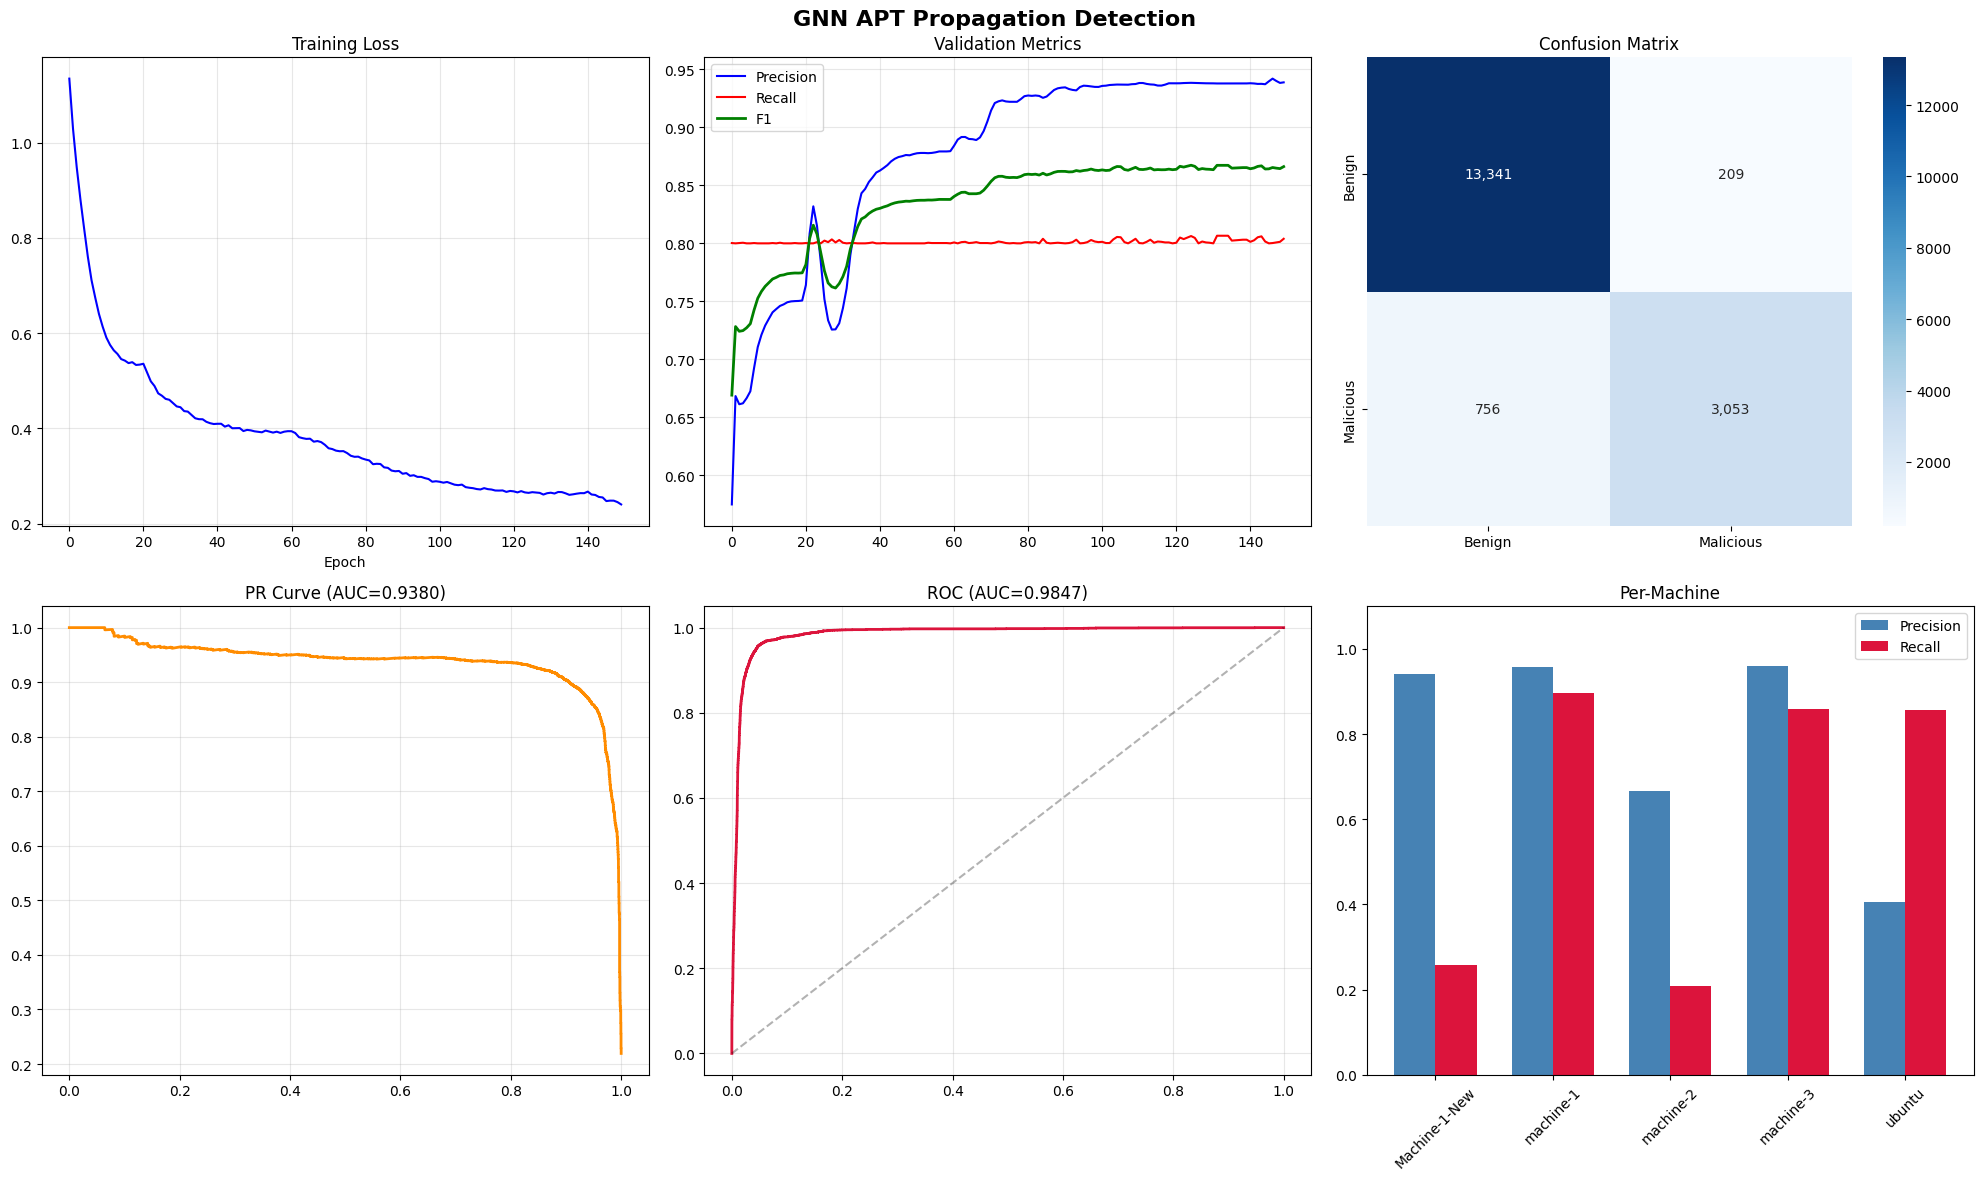

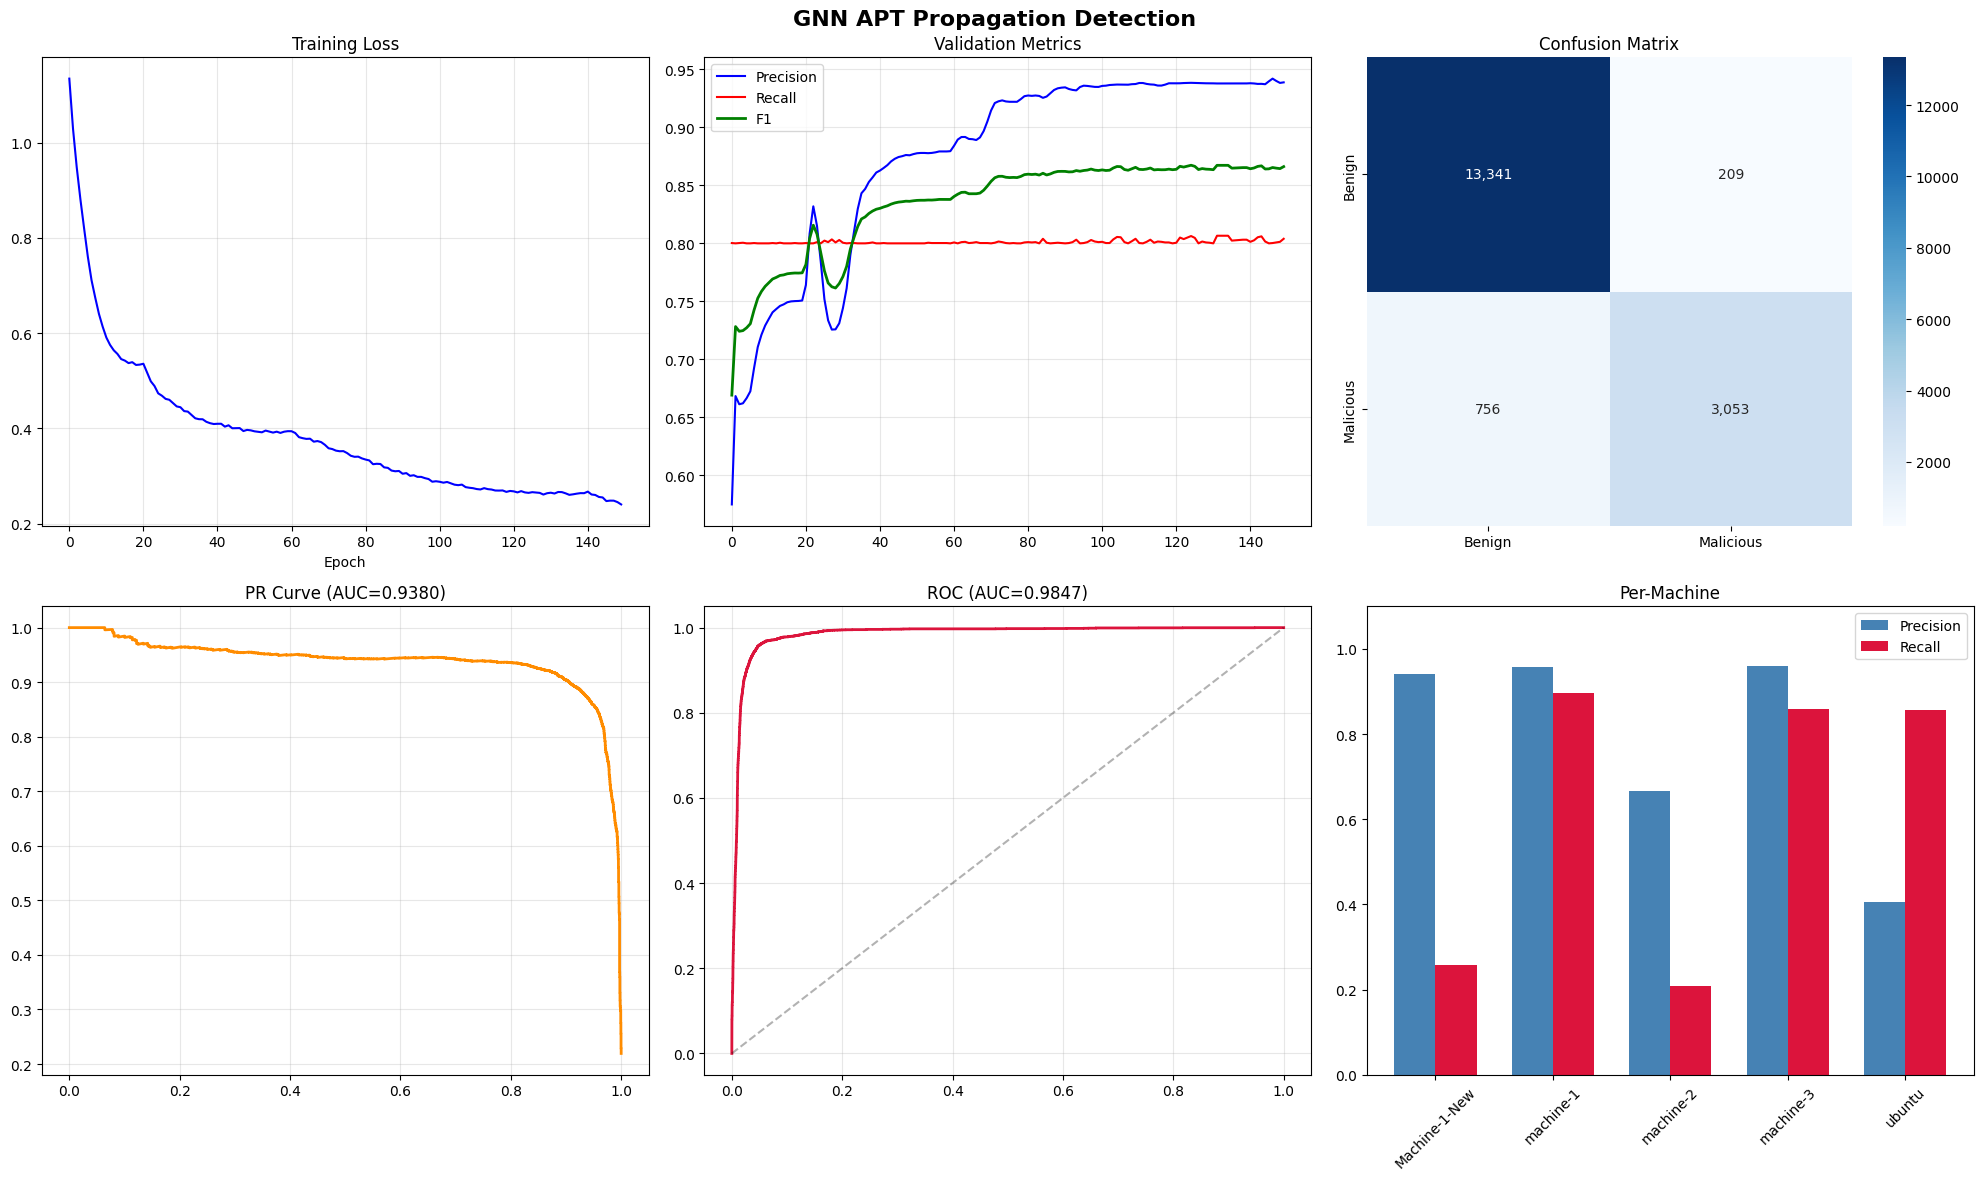


Graph: 115,726 nodes, 1,303,244 edges
Features: 56 dims | Model: 89,345 params
P=0.9359 R=0.8015 F1=0.8635 AUC=0.9847
Target P>=70%: MET (93.6%)
Target R>=80%: MET (80.2%)


In [11]:

print("\n" + "="*70)
print("SECTION 7: FINAL TEST RESULTS")
print("="*70)

model.load_state_dict(torch.load('gnn_propagation_best.pth', map_location=device))
test_m = evaluate_full(model, graph_data, graph_data.test_mask)

print(f"\n{'='*50}")
print(f"  TEST RESULTS")
print(f"{'='*50}")
print(f"  Precision: {test_m['precision']:.4f}")
print(f"  Recall:    {test_m['recall']:.4f}")
print(f"  F1 Score:  {test_m['f1']:.4f}")
print(f"  Accuracy:  {test_m['accuracy']:.4f}")
print(f"  AUC-ROC:   {test_m['auc_roc']:.4f}")
print(f"  AUC-PR:    {test_m['auc_pr']:.4f}")
print(f"  Threshold: {test_m['threshold']:.4f}")
print(f"{'='*50}")

print(f"\n{classification_report(test_m['y_true'], test_m['y_pred'], target_names=['Benign','Malicious'], digits=4)}")

cm = confusion_matrix(test_m['y_true'], test_m['y_pred'])
print(f"Confusion Matrix: TN={cm[0,0]:,} FP={cm[0,1]:,} FN={cm[1,0]:,} TP={cm[1,1]:,}")

# Plots
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle('GNN APT Propagation Detection', fontsize=16, fontweight='bold')

axes[0,0].plot(history['loss'], 'b-', lw=1.5)
axes[0,0].set_title('Training Loss'); axes[0,0].set_xlabel('Epoch'); axes[0,0].grid(True, alpha=0.3)

axes[0,1].plot(history['val_p'], 'b-', label='Precision')
axes[0,1].plot(history['val_r'], 'r-', label='Recall')
axes[0,1].plot(history['val_f1'], 'g-', label='F1', lw=2)
axes[0,1].set_title('Validation Metrics'); axes[0,1].legend(); axes[0,1].grid(True, alpha=0.3)

sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=axes[0,2],
            xticklabels=['Benign','Malicious'], yticklabels=['Benign','Malicious'])
axes[0,2].set_title('Confusion Matrix')

p, r, _ = precision_recall_curve(test_m['y_true'], test_m['y_prob'])
axes[1,0].plot(r, p, 'darkorange', lw=2)
axes[1,0].set_title(f'PR Curve (AUC={test_m["auc_pr"]:.4f})'); axes[1,0].grid(True, alpha=0.3)

fpr, tpr, _ = roc_curve(test_m['y_true'], test_m['y_prob'])
axes[1,1].plot(fpr, tpr, 'crimson', lw=2); axes[1,1].plot([0,1],[0,1],'k--',alpha=0.3)
axes[1,1].set_title(f'ROC (AUC={test_m["auc_roc"]:.4f})'); axes[1,1].grid(True, alpha=0.3)

# Per-machine
test_idx = graph_data.test_mask.cpu().numpy().nonzero()[0]
tdf = df_raw.iloc[test_idx].copy()
tdf['pred'] = test_m['y_pred']
mm = []
for m in sorted(tdf['machine_name'].unique()):
    md = tdf[tdf['machine_name']==m]
    mm.append({'machine':m, 'total':len(md), 'mal':int(md['label'].sum()),
               'P':precision_score(md['label'],md['pred'],zero_division=0),
               'R':recall_score(md['label'],md['pred'],zero_division=0)})
mm_df = pd.DataFrame(mm)
x_pos = range(len(mm_df))
axes[1,2].bar([p-.175 for p in x_pos], mm_df['P'], .35, label='Precision', color='steelblue')
axes[1,2].bar([p+.175 for p in x_pos], mm_df['R'], .35, label='Recall', color='crimson')
axes[1,2].set_xticks(list(x_pos)); axes[1,2].set_xticklabels(mm_df['machine'], rotation=45)
axes[1,2].legend(); axes[1,2].set_title('Per-Machine'); axes[1,2].set_ylim([0,1.1])
print(f"\nPer-Machine:\n{mm_df.to_string(index=False)}")

plt.tight_layout()
plt.savefig('gnn_propagation_results.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary
print(f"\n{'='*50}")
print(f"Graph: {n_nodes:,} nodes, {total_edges:,} edges")
print(f"Features: {in_feat} dims | Model: {sum(p.numel() for p in model.parameters()):,} params")
print(f"P={test_m['precision']:.4f} R={test_m['recall']:.4f} F1={test_m['f1']:.4f} AUC={test_m['auc_roc']:.4f}")
tp = test_m['precision'] >= 0.70
tr = test_m['recall'] >= 0.80
print(f"Target P>=70%: {'MET' if tp else 'MISSED'} ({test_m['precision']*100:.1f}%)")
print(f"Target R>=80%: {'MET' if tr else 'MISSED'} ({test_m['recall']*100:.1f}%)")

In [9]:
print("\n" + "="*70)
print("SECTION 8: SAVING MODEL & METADATA")
print("="*70)

import pickle

# Define paths
MODEL_SAVE_PATH = 'gnn_propagation_final.pth'
METADATA_SAVE_PATH = 'gnn_propagation_metadata.pkl'

# 1. Save strictly the PyTorch state dict of the model
torch.save(model.state_dict(), MODEL_SAVE_PATH)
print(f"Model state dict saved to: {MODEL_SAVE_PATH}")

# 2. Save necessary objects for inference (scaler, threshold, features utilized, etc.)
metadata = {
    'features': selected_cols,       # Ordered list of the 55 selected features
    'rule_level_included': True,     # Rule level flag
    'scaler': scaler,                # Fitted StandardScaler
    'threshold': test_m['threshold'],# Best threshold configured to hit constraints
    'metrics': {
        'precision': test_m['precision'],
        'recall': test_m['recall'],
        'f1': test_m['f1'],
        'auc_roc': test_m['auc_roc']
    },
    'model_params': {
        'in_ch': in_feat,
        'hid': 128,
        'layers': 3,
        'drop': 0.3
    },
    'graph_params': {
        'intra_window_sec': INTRA_WINDOW_SEC,
        'cross_window_sec': CROSS_WINDOW_SEC,
        'max_intra': MAX_INTRA,
        'max_cross': MAX_CROSS
    }
}

with open(METADATA_SAVE_PATH, 'wb') as f:
    pickle.dump(metadata, f)

print(f"Metadata (Scaler, Threshold, Features structure) saved to: {METADATA_SAVE_PATH}")
print("\n✅ Successfully exported model ready for inference engine.")



SECTION 8: SAVING MODEL & METADATA
Model state dict saved to: gnn_propagation_final.pth
Metadata (Scaler, Threshold, Features structure) saved to: gnn_propagation_metadata.pkl

✅ Successfully exported model ready for inference engine.



SECTION 8: NETWORK VISUALIZATION & ANALYSIS

--- Visualizing Local Graph Sub-Structure ---


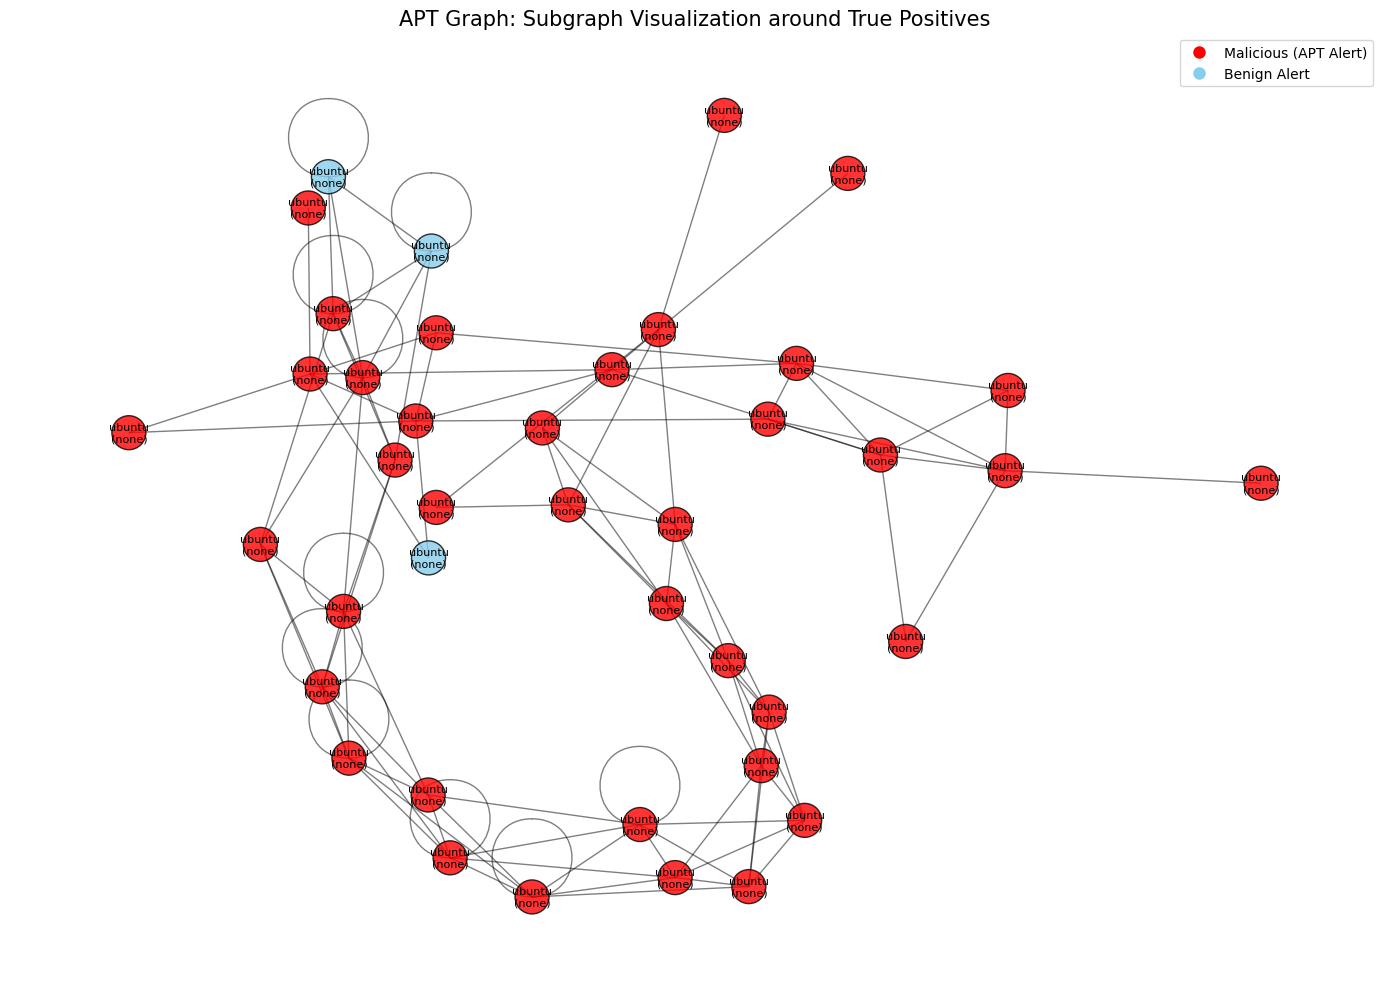


--- Graph Edge Connectivity Distribution ---


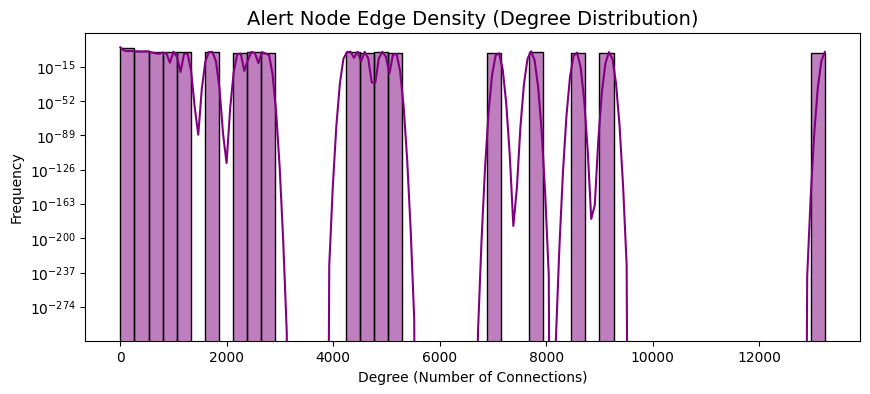

In [12]:
print("\n" + "="*70)
print("SECTION 8: NETWORK VISUALIZATION & ANALYSIS")
print("="*70)

import networkx as nx
from matplotlib.lines import Line2D

# Setup matplotlib to render inline
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)

def visualize_lateral_movement_subgraph(n_samples=50):
    """Visualizes a small sub-graph focusing on cross-machine lateral movement edges."""
    G = nx.Graph()
    
    # We sample a few critical malicious edges (from predictions)
    malicious_indices = np.where((test_m['y_pred'] == 1) & (test_m['y_true'] == 1))[0]
    
    if len(malicious_indices) == 0:
        print("No True Positives to visualize lateral movement.")
        return
        
    start_idx = malicious_indices[0] # Pick the first successful hit
    
    # Gather a small subset of edges from edge_index where nodes are close to start_idx
    edge_src_np = graph_data.edge_index[0].cpu().numpy()
    edge_dst_np = graph_data.edge_index[1].cpu().numpy()

    # Find edges connecting to our sample True Positives
    mask = np.isin(edge_src_np, malicious_indices[:n_samples]) | np.isin(edge_dst_np, malicious_indices[:n_samples])
    
    sub_src = edge_src_np[mask][:200]
    sub_dst = edge_dst_np[mask][:200]
    
    # Add nodes and edges
    for s, d in zip(sub_src, sub_dst):
        G.add_edge(s, d)
        
    colors = []
    node_labels = {}
    for node in G.nodes():
        node = int(node)
        # Benign vs Malicious vs Predicted
        if y_labels[node] == 1:
            colors.append('red') # True Malicious
        else:
            colors.append('skyblue') # True Benign
            
        machine = df_raw.iloc[node]['machine_name']
        user = df_raw.iloc[node]['src_user']
        node_labels[node] = f"{machine}\n({user})"

    plt.figure(figsize=(14, 10))
    pos = nx.spring_layout(G, k=0.5, iterations=50)
    
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=600, alpha=0.8, edgecolors='k')
    nx.draw_networkx_edges(G, pos, alpha=0.5, width=1.0)
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8)
    
    custom_lines = [Line2D([0], [0], marker='o', color='w', label='Malicious (APT Alert)', markerfacecolor='red', markersize=10),
                    Line2D([0], [0], marker='o', color='w', label='Benign Alert', markerfacecolor='skyblue', markersize=10)]
                    
    plt.legend(handles=custom_lines, loc='upper right')
    plt.title('APT Graph: Subgraph Visualization around True Positives', fontsize=15)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

print("\n--- Visualizing Local Graph Sub-Structure ---")
visualize_lateral_movement_subgraph(n_samples=25)


# Also display edge density Distribution
print("\n--- Graph Edge Connectivity Distribution ---")
edge_counts = np.bincount(graph_data.edge_index[0].cpu().numpy())
plt.figure(figsize=(10, 4))
sns.histplot(edge_counts, bins=50, kde=True, color="purple")
plt.title("Alert Node Edge Density (Degree Distribution)", fontsize=14)
plt.xlabel("Degree (Number of Connections)")
plt.ylabel("Frequency")
plt.yscale('log')
plt.show()



                 PART 2: RETRAINING WITHOUT RULE LEVEL FEATURE
Original feature dimensions: 56
New feature dimensions (without rule_level): 55

Model parameters (No Rule Level): 89,089
Training on full graph without 'rule_level'...
Ep   1 | Loss 1.0742 | P=0.432 R=0.800 F1=0.561 AUC=0.825
Ep   2 | Loss 1.0064 | P=0.487 R=0.800 F1=0.605 AUC=0.853
Ep   3 | Loss 0.9488 | P=0.505 R=0.803 F1=0.620 AUC=0.862
Ep   5 | Loss 0.8478 | P=0.533 R=0.800 F1=0.640 AUC=0.877
Ep  10 | Loss 0.7241 | P=0.566 R=0.801 F1=0.663 AUC=0.888
Ep  15 | Loss 0.6940 | P=0.578 R=0.800 F1=0.671 AUC=0.892
Ep  20 | Loss 0.6827 | P=0.581 R=0.800 F1=0.673 AUC=0.893
Ep  25 | Loss 0.6427 | P=0.636 R=0.801 F1=0.709 AUC=0.910
Ep  30 | Loss 0.5998 | P=0.643 R=0.801 F1=0.713 AUC=0.920
Ep  35 | Loss 0.5668 | P=0.656 R=0.800 F1=0.721 AUC=0.929
Ep  40 | Loss 0.5465 | P=0.674 R=0.800 F1=0.732 AUC=0.933
Ep  45 | Loss 0.5359 | P=0.686 R=0.801 F1=0.739 AUC=0.936
Ep  50 | Loss 0.5239 | P=0.695 R=0.801 F1=0.744 AUC=0.939
Ep  55 | Loss

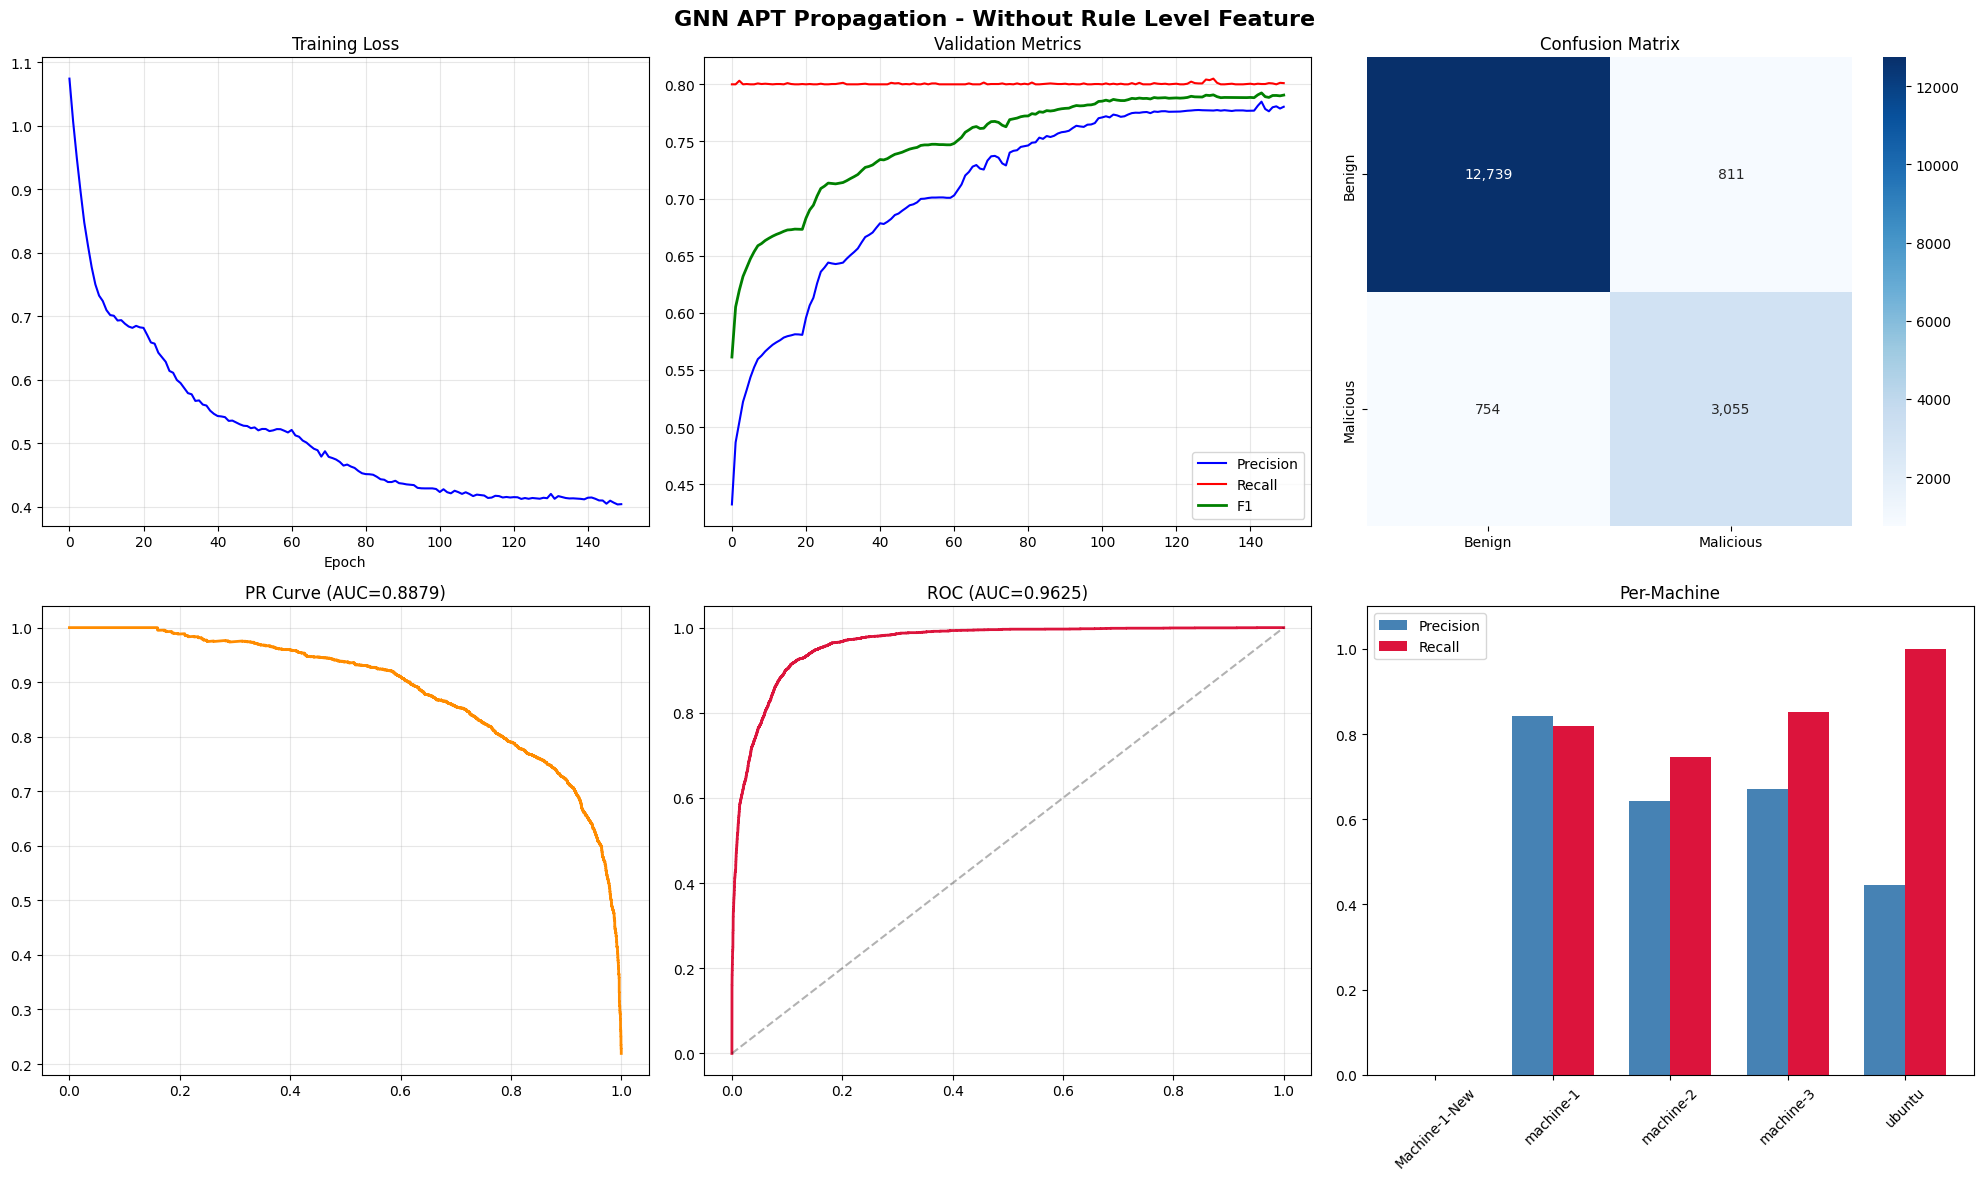

Target P>=70%: MET (79.0%)
Target R>=80%: MET (80.2%)


In [13]:
print("\n" + "="*100)
print("                 PART 2: RETRAINING WITHOUT RULE LEVEL FEATURE")
print("="*100)

# 1. Remove 'rule_level' from the features
# Since rule_level was appended as the last column in X_sel, we slice it out.
X_scaled_no_rule = X_scaled[:, :-1]
in_feat_no_rule = X_scaled_no_rule.shape[1]

print(f"Original feature dimensions: {X_scaled.shape[1]}")
print(f"New feature dimensions (without rule_level): {in_feat_no_rule}")

# Build new PyG Data
x_no_rule = torch.tensor(X_scaled_no_rule, dtype=torch.float)
graph_data_no_rule = Data(x=x_no_rule, edge_index=edge_index, y=y,
                          train_mask=train_mask, val_mask=val_mask, test_mask=test_mask).to(device)

# 2. Model Initialization
model_no_rule = APTPropagationGNN(in_ch=in_feat_no_rule, hid=128, layers=3, drop=0.3).to(device)
print(f"\nModel parameters (No Rule Level): {sum(p.numel() for p in model_no_rule.parameters()):,}")

optimizer_no_rule = torch.optim.AdamW(model_no_rule.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_no_rule = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer_no_rule, T_0=20, T_mult=2)

best_val_f1_nr, best_epoch_nr, patience_ctr_nr = 0.0, 0, 0
history_nr = {'loss':[], 'val_f1':[], 'val_p':[], 'val_r':[]}

print(f"Training on full graph without 'rule_level'...")
for epoch in range(1, NUM_EPOCHS + 1):
    model_no_rule.train()
    optimizer_no_rule.zero_grad()
    logits = model_no_rule(graph_data_no_rule.x, graph_data_no_rule.edge_index)
    loss = criterion(logits[graph_data_no_rule.train_mask], graph_data_no_rule.y[graph_data_no_rule.train_mask])
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model_no_rule.parameters(), 1.0)
    optimizer_no_rule.step()
    scheduler_no_rule.step(epoch)
    
    history_nr['loss'].append(loss.item())
    
    val_m = evaluate_full(model_no_rule, graph_data_no_rule, graph_data_no_rule.val_mask)
    history_nr['val_f1'].append(val_m['f1'])
    history_nr['val_p'].append(val_m['precision'])
    history_nr['val_r'].append(val_m['recall'])
    
    if epoch % 5 == 0 or epoch <= 3:
        print(f"Ep {epoch:3d} | Loss {loss.item():.4f} | P={val_m['precision']:.3f} R={val_m['recall']:.3f} F1={val_m['f1']:.3f} AUC={val_m['auc_roc']:.3f}")
    
    if val_m['f1'] > best_val_f1_nr:
        best_val_f1_nr = val_m['f1']
        best_epoch_nr = epoch
        patience_ctr_nr = 0
        torch.save(model_no_rule.state_dict(), 'gnn_propagation_best_no_rule.pth')
    else:
        patience_ctr_nr += 1
        if patience_ctr_nr >= PATIENCE:
            print(f"\nEarly stop at {epoch} (best: {best_epoch_nr})")
            break

print(f"\nTraining done. Best val F1: {best_val_f1_nr:.4f} at epoch {best_epoch_nr}")

# 3. Final Test Evaluation & Plots
print("\n" + "="*50)
print("  FINAL TEST RESULTS (NO RULE LEVEL)")
print("="*50)

model_no_rule.load_state_dict(torch.load('gnn_propagation_best_no_rule.pth', map_location=device))
test_m_nr = evaluate_full(model_no_rule, graph_data_no_rule, graph_data_no_rule.test_mask)

print(f"  Precision: {test_m_nr['precision']:.4f}")
print(f"  Recall:    {test_m_nr['recall']:.4f}")
print(f"  F1 Score:  {test_m_nr['f1']:.4f}")
print(f"  Accuracy:  {test_m_nr['accuracy']:.4f}")
print(f"  AUC-ROC:   {test_m_nr['auc_roc']:.4f}")
print(f"  AUC-PR:    {test_m_nr['auc_pr']:.4f}")
print(f"  Threshold: {test_m_nr['threshold']:.4f}")
print("="*50)

print(f"\n{classification_report(test_m_nr['y_true'], test_m_nr['y_pred'], target_names=['Benign','Malicious'], digits=4)}")

cm_nr = confusion_matrix(test_m_nr['y_true'], test_m_nr['y_pred'])

# Plots
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle('GNN APT Propagation - Without Rule Level Feature', fontsize=16, fontweight='bold')

axes[0,0].plot(history_nr['loss'], 'b-', lw=1.5)
axes[0,0].set_title('Training Loss'); axes[0,0].set_xlabel('Epoch'); axes[0,0].grid(True, alpha=0.3)

axes[0,1].plot(history_nr['val_p'], 'b-', label='Precision')
axes[0,1].plot(history_nr['val_r'], 'r-', label='Recall')
axes[0,1].plot(history_nr['val_f1'], 'g-', label='F1', lw=2)
axes[0,1].set_title('Validation Metrics'); axes[0,1].legend(); axes[0,1].grid(True, alpha=0.3)

sns.heatmap(cm_nr, annot=True, fmt=',d', cmap='Blues', ax=axes[0,2],
            xticklabels=['Benign','Malicious'], yticklabels=['Benign','Malicious'])
axes[0,2].set_title('Confusion Matrix')

p_nr, r_nr, _ = precision_recall_curve(test_m_nr['y_true'], test_m_nr['y_prob'])
axes[1,0].plot(r_nr, p_nr, 'darkorange', lw=2)
axes[1,0].set_title(f'PR Curve (AUC={test_m_nr["auc_pr"]:.4f})'); axes[1,0].grid(True, alpha=0.3)

fpr_nr, tpr_nr, _ = roc_curve(test_m_nr['y_true'], test_m_nr['y_prob'])
axes[1,1].plot(fpr_nr, tpr_nr, 'crimson', lw=2); axes[1,1].plot([0,1],[0,1],'k--',alpha=0.3)
axes[1,1].set_title(f'ROC (AUC={test_m_nr["auc_roc"]:.4f})'); axes[1,1].grid(True, alpha=0.3)

# Per-machine
tdf_nr = df_raw.iloc[test_idx].copy()
tdf_nr['pred'] = test_m_nr['y_pred']
mm_nr = []
for m in sorted(tdf_nr['machine_name'].unique()):
    md = tdf_nr[tdf_nr['machine_name']==m]
    mm_nr.append({'machine':m, 'total':len(md), 'mal':int(md['label'].sum()),
               'P':precision_score(md['label'],md['pred'],zero_division=0),
               'R':recall_score(md['label'],md['pred'],zero_division=0)})
mm_df_nr = pd.DataFrame(mm_nr)
x_pos = range(len(mm_df_nr))
axes[1,2].bar([pos-.175 for pos in x_pos], mm_df_nr['P'], .35, label='Precision', color='steelblue')
axes[1,2].bar([pos+.175 for pos in x_pos], mm_df_nr['R'], .35, label='Recall', color='crimson')
axes[1,2].set_xticks(list(x_pos)); axes[1,2].set_xticklabels(mm_df_nr['machine'], rotation=45)
axes[1,2].legend(); axes[1,2].set_title('Per-Machine'); axes[1,2].set_ylim([0,1.1])

plt.tight_layout()
plt.savefig('gnn_propagation_results_no_rule.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Target P>=70%: {'MET' if test_m_nr['precision'] >= 0.70 else 'MISSED'} ({test_m_nr['precision']*100:.1f}%)")
print(f"Target R>=80%: {'MET' if test_m_nr['recall'] >= 0.80 else 'MISSED'} ({test_m_nr['recall']*100:.1f}%)")

In [14]:
print("\n" + "="*100)
print("                 PART 3: EXTRACTING GNN FEATURES FOR RL AGENT")
print("="*100)

# 1. Get raw probabilities from our finished model (we'll use the no-rule model)
model_no_rule.eval()
with torch.no_grad():
    logits = model_no_rule(graph_data_no_rule.x, graph_data_no_rule.edge_index)
    alert_risks = torch.sigmoid(logits).cpu().numpy()

# 2. Build a mapping dataframe
df_rl = df_raw[['timestamp', 'machine_name']].copy()
df_rl['alert_risk'] = alert_risks
df_rl['is_high_risk'] = (alert_risks >= test_m_nr['threshold']).astype(int)

# Pre-extract edges for fast neighbor lookups
src_nodes = graph_data_no_rule.edge_index[0].cpu().numpy()
dst_nodes = graph_data_no_rule.edge_index[1].cpu().numpy()

def get_rl_state_features(target_machine, current_time, window_minutes=60):
    """
    Called by the RL Environment at 'current_time' for a specific 'target_machine'.
    Generates the exact GNN features required for the RL Agent's observation space.
    """
    start_time = current_time - pd.Timedelta(minutes=window_minutes)
    prev_start_time = start_time - pd.Timedelta(minutes=window_minutes)
    
    # Masks for current and previous time windows
    curr_mask = (df_rl['timestamp'] > start_time) & (df_rl['timestamp'] <= current_time)
    prev_mask = (df_rl['timestamp'] > prev_start_time) & (df_rl['timestamp'] <= start_time)
    
    curr_indices = np.where(curr_mask)[0]
    prev_indices = np.where(prev_mask)[0]
    
    if len(curr_indices) == 0:
        return {
            "GNN_node_risk_current_host": 0.0, "GNN_neighbor_risk": 0.0,
            "global_graph_risk": 0.0, "high_risk_ratio": 0.0, "risk_growth": 0.0
        }
        
    # Base Global Graph features
    global_graph_risk = df_rl.iloc[curr_indices]['alert_risk'].mean()
    high_risk_ratio = df_rl.iloc[curr_indices]['is_high_risk'].mean()
    
    if len(prev_indices) > 0:
        prev_global_risk = df_rl.iloc[prev_indices]['alert_risk'].mean()
        risk_growth = global_graph_risk - prev_global_risk
    else:
        risk_growth = global_graph_risk
        
    # Target Machine specific features
    host_mask = curr_mask & (df_rl['machine_name'] == target_machine)
    host_indices = np.where(host_mask)[0]
    
    if len(host_indices) > 0:
        GNN_node_risk_current_host = df_rl.iloc[host_indices]['alert_risk'].mean()
        
        # Locate neighbors (lateral connections) connected to the host's nodes
        neighbor_mask = np.isin(src_nodes, host_indices)
        neighbor_indices = np.unique(dst_nodes[neighbor_mask])
        
        # Target external connected machines only (remove alerts on the host itself)
        external_neighbors = np.setdiff1d(neighbor_indices, host_indices)
        
        if len(external_neighbors) > 0:
            GNN_neighbor_risk = df_rl.iloc[external_neighbors]['alert_risk'].mean()
        else:
            GNN_neighbor_risk = 0.0
    else:
        GNN_node_risk_current_host = 0.0
        GNN_neighbor_risk = 0.0
        
    return {
        "GNN_node_risk_current_host": float(GNN_node_risk_current_host),
        "GNN_neighbor_risk": float(GNN_neighbor_risk),
        "global_graph_risk": float(global_graph_risk),
        "high_risk_ratio": float(high_risk_ratio),
        "risk_growth": float(risk_growth)
    }

# -----------------
# Let's test it!
# -----------------
sample_time = df_rl['timestamp'].median()
sample_machine = 'machine-1'

print(f"Testing Interface: \n  At time: {sample_time}\n  To machine: '{sample_machine}'\n")

rl_features = get_rl_state_features(target_machine=sample_machine, current_time=sample_time, window_minutes=60)

for feature_name, value in rl_features.items():
    print(f"  > {feature_name}: {value:.5f}")


                 PART 3: EXTRACTING GNN FEATURES FOR RL AGENT
Testing Interface: 
  At time: 2023-12-26 17:40:16.598499840
  To machine: 'machine-1'

  > GNN_node_risk_current_host: 0.03544
  > GNN_neighbor_risk: 0.03333
  > global_graph_risk: 0.03542
  > high_risk_ratio: 0.00000
  > risk_growth: 0.03542


In [15]:
print("\n" + "="*100)
print("                 PART 4: VALIDATING RL FEATURES (HIGH RISK vs LOW RISK)")
print("="*100)

# Re-attach target labels to df_rl to easily find correct predictions
df_rl['true_label'] = df_raw['label'].values
df_rl['prediction'] = (df_rl['alert_risk'] >= test_m_nr['threshold']).astype(int)

# 1. Find a TRUE POSITIVE (High Risk Malicious Activity - Correctly Predicted)
tp_candidates = df_rl[(df_rl['true_label'] == 1) & (df_rl['prediction'] == 1)]
if len(tp_candidates) > 0:
    tp_sample = tp_candidates.iloc[len(tp_candidates)//2] # Pick one from the middle
    tp_time = tp_sample['timestamp']
    tp_machine = tp_sample['machine_name']
    print(f"\n[HIGH RISK EXAMPLE - TRUE POSITIVE]")
    print(f"Timestamp: {tp_time} | Machine: {tp_machine}")
    print(f"Ground Truth: Malicious (1) | GNN Alert Prediction: High Risk (1) | Raw Node Risk Output: {tp_sample['alert_risk']:.4f}")
    
    rl_features_tp = get_rl_state_features(target_machine=tp_machine, current_time=tp_time, window_minutes=60)
    print("RL Output State Variables (Window: 60m):")
    for k, v in rl_features_tp.items():
        print(f"  > {k}: {v:.5f}")

# 2. Find a TRUE NEGATIVE (Low Risk Benign Activity - Correctly Predicted)
tn_candidates = df_rl[(df_rl['true_label'] == 0) & (df_rl['prediction'] == 0)]
if len(tn_candidates) > 0:
    tn_sample = tn_candidates.iloc[len(tn_candidates)//2] # Pick one from the middle
    tn_time = tn_sample['timestamp']
    tn_machine = tn_sample['machine_name']
    print(f"\n[LOW RISK EXAMPLE - TRUE NEGATIVE]")
    print(f"Timestamp: {tn_time} | Machine: {tn_machine}")
    print(f"Ground Truth: Benign (0) | GNN Alert Prediction: Low Risk (0) | Raw Node Risk Output: {tn_sample['alert_risk']:.4f}")
    
    rl_features_tn = get_rl_state_features(target_machine=tn_machine, current_time=tn_time, window_minutes=60)
    print("RL Output State Variables (Window: 60m):")
    for k, v in rl_features_tn.items():
        print(f"  > {k}: {v:.5f}")


                 PART 4: VALIDATING RL FEATURES (HIGH RISK vs LOW RISK)

[HIGH RISK EXAMPLE - TRUE POSITIVE]
Timestamp: 2023-10-05 20:22:57.510000 | Machine: machine-1
Ground Truth: Malicious (1) | GNN Alert Prediction: High Risk (1) | Raw Node Risk Output: 0.9925
RL Output State Variables (Window: 60m):
  > GNN_node_risk_current_host: 0.96358
  > GNN_neighbor_risk: 0.99267
  > global_graph_risk: 0.96358
  > high_risk_ratio: 0.97994
  > risk_growth: 0.04667

[LOW RISK EXAMPLE - TRUE NEGATIVE]
Timestamp: 2023-12-28 15:57:35.550000 | Machine: machine-1
Ground Truth: Benign (0) | GNN Alert Prediction: Low Risk (0) | Raw Node Risk Output: 0.0503
RL Output State Variables (Window: 60m):
  > GNN_node_risk_current_host: 0.08180
  > GNN_neighbor_risk: 0.05969
  > global_graph_risk: 0.08239
  > high_risk_ratio: 0.00000
  > risk_growth: 0.08239
